**importing the required libraries**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn import preprocessing
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
from sklearn.tree import plot_tree
from sklearn import tree
import sklearn.datasets as datasets
%matplotlib inline

**Importing the  iris dataset**

In [2]:
df=pd.read_csv('Iris.csv')
df

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica


In [3]:
df.columns

Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='str')

In [4]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


**pre processing of Data**

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 9.1 KB


In [6]:
df.tail()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica
149,150,5.9,3.0,5.1,1.8,Iris-virginica


In [7]:
df.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [8]:
df.columns.tolist()

['Id',
 'SepalLengthCm',
 'SepalWidthCm',
 'PetalLengthCm',
 'PetalWidthCm',
 'Species']

**Checking out the null values in the dataset**

In [9]:
df.isnull().sum()

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

The variables have no missing values

**Visualing the sepal and petal dimension**

In [10]:
sns.set_style("darkgrid")

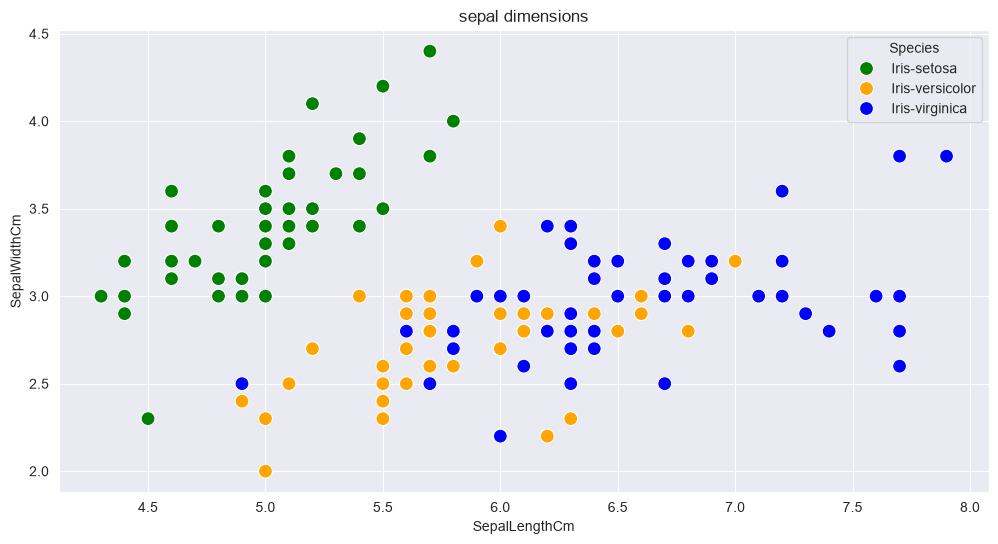

In [11]:
plt.figure(figsize=(12,6))
plt.title('sepal dimensions')
sns.scatterplot(
    x=df["SepalLengthCm"],
     y=df["SepalWidthCm"],
    hue=df["Species"],
    palette=["green","orange","blue"],
                s=100
)
plt.show()

the plt gives information the species "0" has small sepal length and large sepal width and wherespecies "2" has large sepal length and small sepal width.In some cases it is very difficultis classify species "1" and species "2" they almost have same sepal dimensions. Here it is easy to seprate species"0"from the other species with linear boundry.but it is not possible to seprate species"1" & "2" with linear boundry and hence requires complex boundry for sepration.

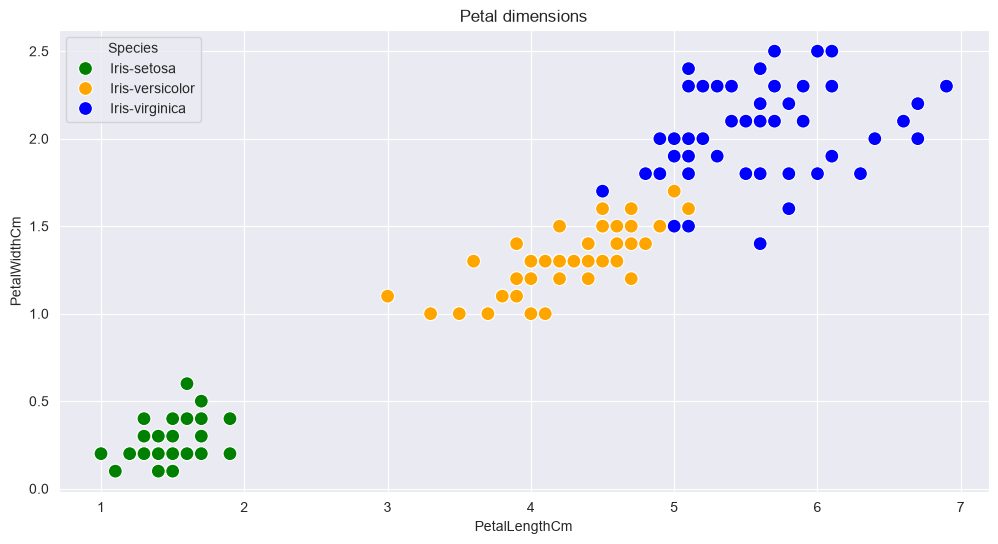

In [12]:
plt.figure(figsize=(12,6))
plt.title('Petal dimensions')
sns.scatterplot(
    x=df["PetalLengthCm"],
     y=df["PetalWidthCm"],
    hue=df["Species"],
    palette=["green","orange","blue"],
                s=100
)
plt.show()

Here species"0" has small Petal length and Petal width while opposite holds true for species"2". It can be observed that there is linear relationship between petal length & petal width for all Species 

**Analysing the distribution of sepal and petal dimensions**

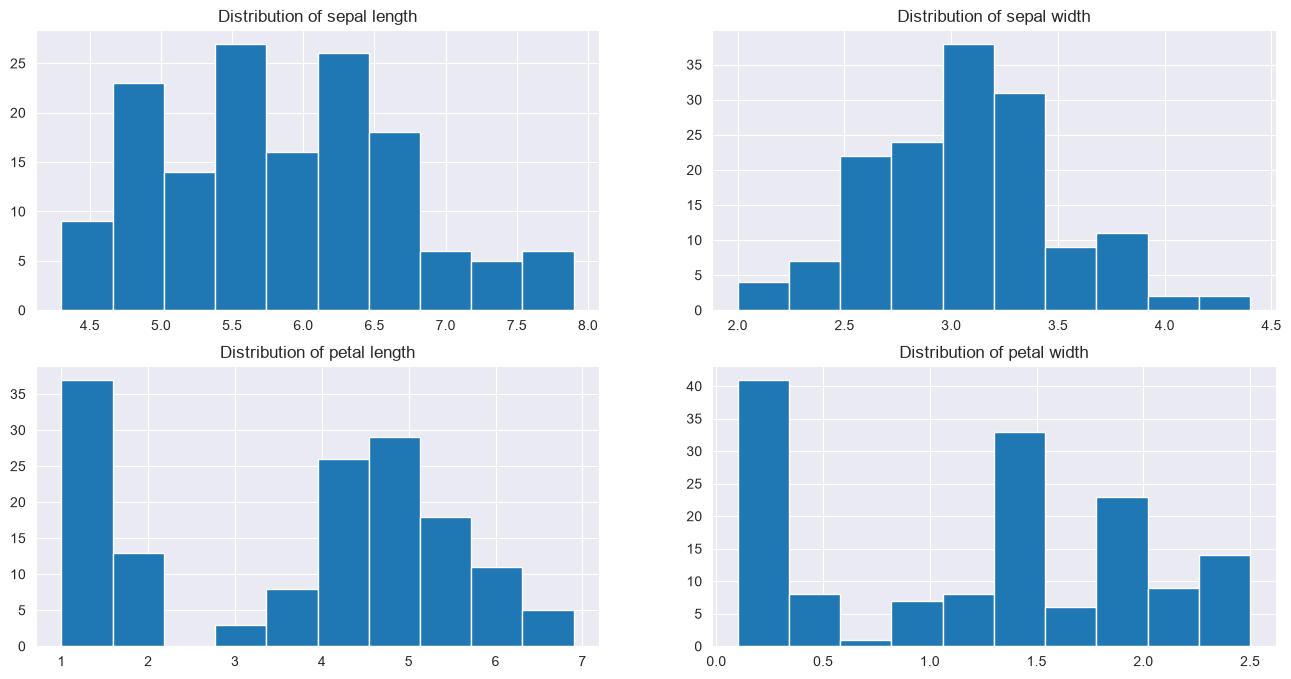

In [13]:
fig,axes = plt.subplots(2,2, figsize=(16,8))
#plot the sepal length
axes[0,0].set_title("Distribution of sepal length")
axes[0,0].hist(df["SepalLengthCm"]);

#plot the sepal width
axes[0,1].set_title("Distribution of sepal width")
axes[0,1].hist(df["SepalWidthCm"]);

#plot the petal length
axes[1,0].set_title("Distribution of petal length")
axes[1,0].hist(df["PetalLengthCm"]);

#plot the petal width
axes[1,1].set_title("Distribution of petal width")
axes[1,1].hist(df["PetalWidthCm"]);




It Observed that sepal width follows normal distribution,while sepal length is lightly right skewed

**Analysing correlation between feature and Target**

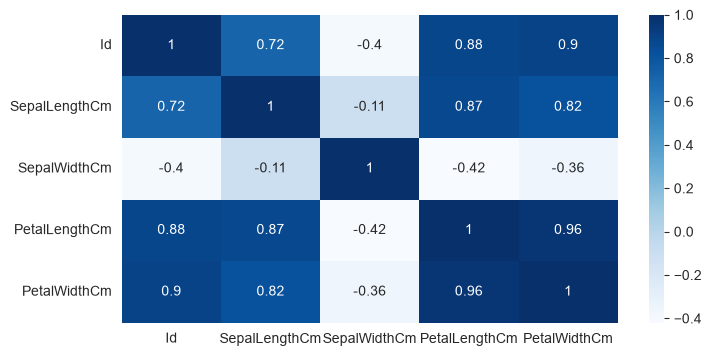

In [14]:
plt.figure(figsize=(8,4))
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap="Blues");

The plot insightes that petal width and lenght are highly correlated,while the sepal length and width are not correlated.

**Splitting The Data into Training and Testing Dataset**

In [15]:
train,test=train_test_split(df,test_size=0.2)

In [16]:
train.shape,test.shape 

((120, 6), (30, 6))

In [17]:
df.columns

Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='str')

In [18]:
train_x=train[['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']]
train_y=train.Species


In [19]:
test_x=test[['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']]
test_y=test.Species


In [20]:
dtree=DecisionTreeClassifier()
dtree.fit(train_x,train_y)
predictions = dtree.predict(test_x)
print("The accuracy of Decision Tree is:",accuracy_score(predictions,test_y))

The accuracy of Decision Tree is: 1.0


The Decision Tree model achieved an accuracy of 100%, indicating that it correctly classified all the test observations

In [21]:
x=df[['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']]
y=df.Species


In [22]:
dtree1=DecisionTreeClassifier()
dtree1.fit(x,y)
print("Decision Tree Classifier is created")

Decision Tree Classifier is created


**Let us visualize the Decision Tree to understand it better**

In [23]:
# Install required Libraries
!pip install pydotplus


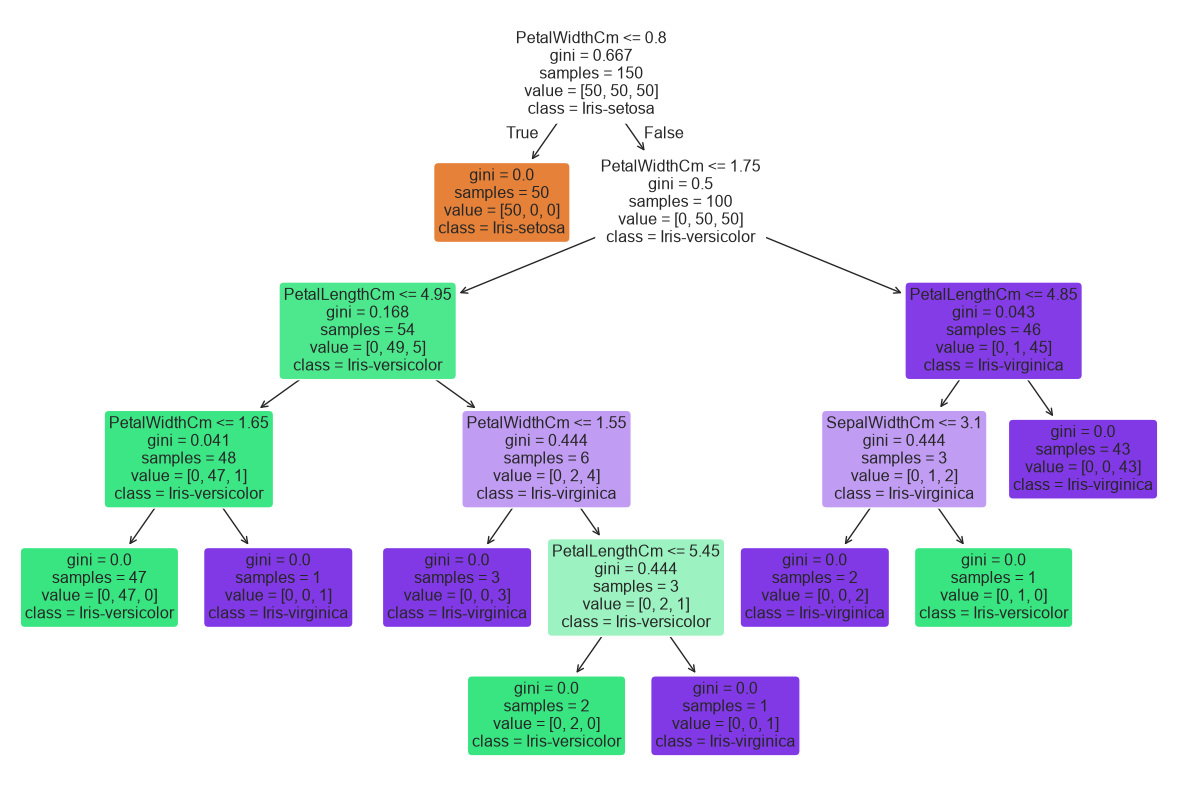

In [28]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
plt.figure(figsize=(15, 10))
plot_tree(dtree1, 
          feature_names=['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm'], 
          class_names=['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'], 
          filled=True, 
          rounded=True)

plt.show()

It is observed thet all theleaf nodes are homogenous